# Evaluate a fine-tuned ResNet-18 on the HAM10000 test set

Scores an existing checkpoint on the 1,035-image test split (the 10% of lesions that training never saw) and produces plots. The model is only loaded and run, never retrained or modified.

Everything runs on **CPU** with a fixed thread count, so FP32 and INT8 (PTQ / QAT) models can be evaluated identically: change the config cell and re-run.

In [1]:
# Configuration: the only cell to edit between runs
MODEL_PATH = "results/qat_int8/resnet18_qat_int8.pt"
MODEL_LABEL = "INT8-QAT"            # "FP32", "INT8-PTQ" or "INT8-QAT"
CONFIG_PATH = "configs/strong_cosine25.yaml"
BATCH_SIZE = 32
NUM_THREADS = 4
RUN_ENERGY = True

In [2]:
import hashlib
import json
import os
import platform
import subprocess
import sys
import threading
import time
from datetime import datetime, timezone
from pathlib import Path

sys.path.insert(0, "src")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch
import torch.nn.functional as F
import torchvision
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

from ham10000.data import build_test_loader, lesion_split
from ham10000.models import build_model
from ham10000.quantize import ENGINE, set_engine
from ham10000.utils import load_config

set_engine()  # INT8 TorchScript models run on the quantized engine they were converted for (oneDNN)

assert MODEL_LABEL in ("FP32", "INT8-PTQ", "INT8-QAT"), MODEL_LABEL
COLOR = {"FP32": "#1f77b4", "INT8-PTQ": "#ff7f0e", "INT8-QAT": "#2ca02c"}[MODEL_LABEL]
OUT_DIR = Path("results") / f"eval_{MODEL_LABEL}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

torch.set_num_threads(NUM_THREADS)
device = torch.device("cpu")
config = load_config(CONFIG_PATH)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "font.size": 9,
})

def save_fig(fig, name):
    """Save a figure as PDF and 300-dpi PNG in OUT_DIR."""
    fig.savefig(OUT_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(OUT_DIR / f"{name}.png", dpi=300, bbox_inches="tight")

print(f"Model: {MODEL_LABEL} ({MODEL_PATH})")
print(f"Device: {device}, torch threads: {torch.get_num_threads()}")
print(f"Outputs: {OUT_DIR}")

Model: INT8-QAT (results/qat_int8/resnet18_qat_int8.pt)
Device: cpu, torch threads: 4
Outputs: results\eval_INT8-QAT


## Test set

`build_test_loader` (in `src/ham10000/data.py`) reuses the exact lesion-level split that `finetune_resnet18.py` trains on, with no augmentation and no shuffling.

In [3]:
test_loader, test_df, class_to_idx = build_test_loader(config, batch_size=BATCH_SIZE)
class_names = [c for c, _ in sorted(class_to_idx.items(), key=lambda kv: kv[1])]

test_df[["image_id", "lesion_id", "dx"]].to_csv("results/test_split.csv", index=False)

# Sanity checks: expected size, and no lesion shared with train or val
assert len(test_df) == 1035, f"expected 1,035 test images, got {len(test_df)}"
full = test_loader.dataset.dataset.data
train_idx, val_idx, test_idx = lesion_split(full, config)
seen_lesions = set(full.loc[train_idx + val_idx, "lesion_id"])
assert not seen_lesions & set(test_df["lesion_id"]), "test lesions overlap train/val"

print(f"Test images: {len(test_df)} ({test_df['lesion_id'].nunique()} lesions), saved to results/test_split.csv")
print(test_df["dx"].value_counts().reindex(class_names).to_string())

Test images: 1035 (747 lesions), saved to results/test_split.csv
dx
akiec     35
bcc       75
bkl      129
df        20
mel       99
nv       663
vasc      14


## Load the model

A raw `state_dict` (as saved by `finetune_resnet18.py`) is loaded into `build_model`. A TorchScript file, e.g. a future INT8 export, is loaded directly.

In [4]:
def load_model(path):
    try:
        model = torch.jit.load(path, map_location="cpu")
    except RuntimeError:
        model = build_model(config.num_classes, config.model_name)
        model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    return model.to(device).eval()

model = load_model(MODEL_PATH)
model_size_mb = os.path.getsize(MODEL_PATH) / 2**20
with open(MODEL_PATH, "rb") as f:
    model_sha256 = hashlib.sha256(f.read()).hexdigest()
print(f"Loaded {type(model).__name__}, file size {model_size_mb:.2f} MB, sha256 {model_sha256[:12]}…")

Loaded RecursiveScriptModule, file size 10.80 MB, sha256 815cdd774d11…


## Predictions

In [5]:
probs, labels = [], []
t0 = time.perf_counter()
with torch.inference_mode():
    for x, y in test_loader:
        probs.append(F.softmax(model(x.to(device)), dim=1).numpy())
        labels.append(y.numpy())
print(f"Inference over the test set took {time.perf_counter() - t0:.1f} s (including image loading)")

y_prob = np.concatenate(probs)
y_true = np.concatenate(labels)
y_pred = y_prob.argmax(axis=1)

predictions = pd.DataFrame({
    "image_id": test_df["image_id"],
    "true": [class_names[i] for i in y_true],
    "predicted": [class_names[i] for i in y_pred],
    **{f"prob_{c}": y_prob[:, i] for i, c in enumerate(class_names)},
})
predictions.to_csv(OUT_DIR / "predictions.csv", index=False)
predictions.head()

Inference over the test set took 18.2 s (including image loading)


,image_id,true,predicted,prob_akiec,prob_bcc,prob_bkl,prob_df,prob_mel,prob_nv,prob_vasc
0,ISIC_0027419,bkl,bkl,0.000783,0.000205,0.996898,0.000002,0.001055,0.001055,1.745263e-06
1,ISIC_0025030,bkl,bkl,0.000131,0.000072,0.998836,0.000004,0.000583,0.000373,6.164851e-07
2,ISIC_0025076,bkl,nv,0.000556,0.000556,0.006994,0.002466,0.035996,0.953404,2.827903e-05
3,ISIC_0029687,bkl,akiec,0.655424,0.001258,0.024745,0.001695,0.005580,0.311249,4.751255e-05
4,ISIC_0025642,bkl,nv,0.000423,0.000021,0.017504,0.000006,0.140832,0.841196,1.852331e-05


## Performance metrics

Specificity and ROC-AUC are one-vs-rest per class, then macro-averaged. The 95% confidence intervals come from 1,000 bootstrap resamples of the test images.

In [6]:
labels_idx = list(range(len(class_names)))
cm = confusion_matrix(y_true, y_pred, labels=labels_idx)

def specificity_per_class(cm):
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    tn = cm.sum() - tp - fp - fn
    return tn / (tn + fp)

per_class = pd.DataFrame({
    "class": class_names,
    "precision": precision_score(y_true, y_pred, labels=labels_idx, average=None, zero_division=0),
    "recall": recall_score(y_true, y_pred, labels=labels_idx, average=None, zero_division=0),
    "specificity": specificity_per_class(cm),
    "f1": f1_score(y_true, y_pred, labels=labels_idx, average=None, zero_division=0),
    "support": cm.sum(axis=1),
})
per_class.to_csv(OUT_DIR / "per_class_metrics.csv", index=False)

overall = {
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "macro_specificity": float(per_class["specificity"].mean()),
    "macro_auc_ovr": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=labels_idx),
}

# Bootstrap CIs for accuracy, macro F1 and macro AUC
N_BOOT = 1000
rng = np.random.default_rng(0)
boot = {"accuracy": [], "macro_f1": [], "macro_auc_ovr": []}
auc_skipped = 0
for _ in range(N_BOOT):
    idx = rng.integers(0, len(y_true), len(y_true))
    yt, yp, pr = y_true[idx], y_pred[idx], y_prob[idx]
    boot["accuracy"].append(accuracy_score(yt, yp))
    boot["macro_f1"].append(f1_score(yt, yp, average="macro", zero_division=0))
    if len(np.unique(yt)) == len(class_names):  # AUC needs every class in the resample
        boot["macro_auc_ovr"].append(roc_auc_score(yt, pr, multi_class="ovr", average="macro", labels=labels_idx))
    else:
        auc_skipped += 1
ci95 = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in boot.items()}

summary = pd.DataFrame({
    "value": pd.Series(overall),
    "ci95_low": pd.Series({k: v[0] for k, v in ci95.items()}),
    "ci95_high": pd.Series({k: v[1] for k, v in ci95.items()}),
}).reindex(list(overall))
print(summary.round(4).to_string())
if auc_skipped:
    print(f"({auc_skipped} AUC resamples skipped: a class was missing)")
print()
print(per_class.round(4).to_string(index=False))

                    value  ci95_low  ci95_high
accuracy           0.8087    0.7845     0.8329
balanced_accuracy  0.6960       NaN        NaN
macro_precision    0.6813       NaN        NaN
macro_recall       0.6960       NaN        NaN
macro_f1           0.6748    0.6171     0.7227
macro_specificity  0.9617       NaN        NaN
macro_auc_ovr      0.9547    0.9413     0.9663

class  precision  recall  specificity     f1  support
akiec     0.4694  0.6571       0.9740 0.5476       35
  bcc     0.7237  0.7333       0.9781 0.7285       75
  bkl     0.7143  0.6202       0.9647 0.6639      129
   df     0.7273  0.4000       0.9970 0.5161       20
  mel     0.4863  0.7172       0.9199 0.5796       99
   nv     0.9423  0.8869       0.9032 0.9138      663
 vasc     0.7059  0.8571       0.9951 0.7742       14


### Check against `comparaison.md`

The four-way comparison stored its test-set scores in `results/comparison.json`. For the same checkpoint, accuracy and macro F1 should match.

In [7]:
reference = None
if Path("results/comparison.json").exists():
    runs = json.load(open("results/comparison.json"))["runs"].values()
    ckpt_dir = Path(MODEL_PATH).parent.name
    reference = next((r for r in runs if r["dir"] == ckpt_dir), None)

if reference is None:
    print("No reference scores for this checkpoint in results/comparison.json")
else:
    for key in ("accuracy", "macro_f1"):
        ref, now = reference[key], overall[key]
        status = "match" if abs(ref - now) < 1e-9 else f"differ by {now - ref:+.4f}"
        print(f"{key:9s}  comparison.json {ref:.4f}  |  this notebook {now:.4f}  ->  {status}")

No reference scores for this checkpoint in results/comparison.json


## Efficiency

Latency at batch size 1 (30 warm-up + 200 timed runs) and throughput at batch size 32, both on real test images. Memory is the process RSS, sampled every millisecond by a background thread during inference.

In [8]:
x1 = next(iter(test_loader))[0][:1].to(device)
xb = next(iter(test_loader))[0][:32].to(device)

from ptflops import get_model_complexity_info

# ptflops cannot count quantized modules. Quantization changes the precision of the operations,
# not their number, so INT8 models report the MAC count of the FP32 architecture they come from.
flops_model = model if MODEL_LABEL == "FP32" else build_model(config.num_classes, config.model_name).eval()
macs, _ = get_model_complexity_info(flops_model, (3, config.image_size, config.image_size),
                                    as_strings=False, print_per_layer_stat=False, verbose=False)
gmacs = macs / 1e9
gmacs_note = ("counted by ptflops on this model" if MODEL_LABEL == "FP32" else
              "FP32 architecture count: quantization changes the precision of the operations, not their number")
print(f"GMACs: {gmacs:.3f} ({gmacs_note})")

class RSSSampler:
    """Track the peak resident set size of this process while active."""
    def __init__(self, interval=0.001):
        self.proc, self.interval, self.peak = psutil.Process(), interval, 0
    def __enter__(self):
        self.peak, self._stop = self.proc.memory_info().rss, threading.Event()
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()
        return self
    def _run(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, self.proc.memory_info().rss)
            time.sleep(self.interval)
    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()

with torch.inference_mode():
    # Latency, batch size 1
    for _ in range(30):
        model(x1)
    idle_rss = psutil.Process().memory_info().rss
    latency_ms = []
    with RSSSampler() as mem_bs1:
        for _ in range(200):
            t0 = time.perf_counter()
            model(x1)
            latency_ms.append((time.perf_counter() - t0) * 1000)
    latency_ms = np.array(latency_ms)

    # Throughput, batch size 32
    for _ in range(3):
        model(xb)
    n_runs = 20
    with RSSSampler() as mem_bs32:
        t0 = time.perf_counter()
        for _ in range(n_runs):
            model(xb)
        elapsed = time.perf_counter() - t0
    throughput = len(xb) * n_runs / elapsed

pd.DataFrame({"run": np.arange(1, len(latency_ms) + 1), "latency_ms": latency_ms}).to_csv(
    OUT_DIR / "latency_samples.csv", index=False)

efficiency = {
    "model_size_mb": model_size_mb,
    "gmacs": gmacs,
    "gmacs_note": gmacs_note,
    "latency_bs1_ms": {"median": float(np.median(latency_ms)), "p95": float(np.percentile(latency_ms, 95)),
                       "mean": float(latency_ms.mean()), "runs": len(latency_ms), "warmup": 30},
    "throughput_bs32_ips": {"images_per_s": throughput, "batch_size": len(xb), "runs": n_runs},
    "memory_rss_mb": {"idle": idle_rss / 2**20, "peak_bs1": mem_bs1.peak / 2**20, "peak_bs32": mem_bs32.peak / 2**20},
}
print(json.dumps(efficiency, indent=2))

GMACs: 1.825 (FP32 architecture count: quantization changes the precision of the operations, not their number)


{
  "model_size_mb": 10.79748821258545,
  "gmacs": 1.824804359,
  "gmacs_note": "FP32 architecture count: quantization changes the precision of the operations, not their number",
  "latency_bs1_ms": {
    "median": 12.479800003347918,
    "p95": 13.084115006495267,
    "mean": 12.568147500278428,
    "runs": 200,
    "warmup": 30
  },
  "throughput_bs32_ips": {
    "images_per_s": 100.63588988435616,
    "batch_size": 32,
    "runs": 20
  },
  "memory_rss_mb": {
    "idle": 973.2109375,
    "peak_bs1": 973.59765625,
    "peak_bs32": 964.921875
  }
}


## Energy and CO₂e (optional)

The test images are first cached as tensors, so only model inference is measured, not JPEG decoding. Inference loops over the cache for at least 60 s under a CodeCarbon tracker. Only **CPU + RAM** energy is counted, since the model runs on CPU. CO₂e uses the grid carbon intensity CodeCarbon reports for this location.

In [9]:
MEASURED_CPU_MODES = {"intel_rapl", "intel_power_gadget", "windows_emi", "apple_powermetrics"}
energy = None

if RUN_ENERGY:
    from codecarbon import EmissionsTracker

    cache = [x.to(device) for x, _ in test_loader]
    tracker = EmissionsTracker(project_name=f"eval_{MODEL_LABEL}", measure_power_secs=1,
                               log_level="error", save_to_file=False)
    n_images = 0
    with torch.inference_mode():
        tracker.start()
        t0 = time.perf_counter()
        while time.perf_counter() - t0 < 60:
            for x in cache:
                model(x)
                n_images += len(x)
                if time.perf_counter() - t0 >= 60:
                    break
        duration = time.perf_counter() - t0
        tracker.stop()
    del cache

    d = tracker.final_emissions_data
    cpu = next(h for h in tracker._hardware if type(h).__name__ == "CPU")
    cpu_mode = cpu._mode
    cpu_ram_kwh = d.cpu_energy + d.ram_energy
    intensity = d.emissions / d.energy_consumed  # kg CO2e per kWh, from CodeCarbon's grid data
    co2e_kg = cpu_ram_kwh * intensity
    energy = {
        "duration_s": duration,
        "images": n_images,
        "cpu_kwh": d.cpu_energy,
        "ram_kwh": d.ram_energy,
        "cpu_ram_kwh": cpu_ram_kwh,
        "gpu_kwh_excluded": d.gpu_energy,
        "co2e_kg": co2e_kg,
        "wh_per_1000_images": cpu_ram_kwh * 1000 / n_images * 1000,
        "cpu_wh_per_1000_images": d.cpu_energy * 1000 / n_images * 1000,
        "ram_wh_per_1000_images": d.ram_energy * 1000 / n_images * 1000,
        "g_co2e_per_1000_images": co2e_kg * 1000 / n_images * 1000,
        "carbon_intensity_g_per_kwh": intensity * 1000,
        "country": d.country_name,
        "cpu_model": d.cpu_model,
        "cpu_power_mode": cpu_mode,
        "cpu_power_source": "measured" if cpu_mode in MEASURED_CPU_MODES else "estimated (TDP)",
        "tracking_mode": d.tracking_mode,
    }
    print(json.dumps(energy, indent=2))
else:
    print("RUN_ENERGY is False: energy measurement skipped")

[codecarbon WARNING @ 01:13:01] Multiple instances of codecarbon are allowed to run at the same time.


{
  "duration_s": 60.19112020000466,
  "images": 6039,
  "cpu_kwh": 0.000744639208334,
  "ram_kwh": 0.00016693557333338608,
  "cpu_ram_kwh": 0.000911574781667386,
  "gpu_kwh_excluded": 5.1891152624000333e-05,
  "co2e_kg": 0.0005140880675700124,
  "wh_per_1000_images": 0.15094796848275974,
  "cpu_wh_per_1000_images": 0.12330505188508031,
  "ram_wh_per_1000_images": 0.02764291659767943,
  "g_co2e_per_1000_images": 0.08512801251366327,
  "carbon_intensity_g_per_kwh": 563.956,
  "country": "Tunisia",
  "cpu_model": "AMD Ryzen 7 5800H with Radeon Graphics",
  "cpu_power_mode": "windows_emi",
  "cpu_power_source": "measured",
  "tracking_mode": "machine"
}


## Save results

In [10]:
metrics = {
    "model_label": MODEL_LABEL,
    "model_path": MODEL_PATH,
    "test_images": int(len(y_true)),
    "performance": {**overall, "ci95": ci95, "bootstrap_resamples": N_BOOT, "auc_resamples_skipped": auc_skipped},
    "per_class": per_class.set_index("class").to_dict(orient="index"),
    "confusion_matrix": {"labels": class_names, "counts": cm.tolist()},
    "efficiency": efficiency,
    "energy": energy,
}
with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=float)

def package_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

try:
    git_commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True).stdout.strip()
except Exception:
    git_commit = None

settings = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model_label": MODEL_LABEL,
    "model_path": MODEL_PATH,
    "model_sha256": model_sha256,
    "config_path": CONFIG_PATH,
    "test_split_csv": "results/test_split.csv",
    "batch_size": BATCH_SIZE,
    "device": str(device),
    "quantized_engine": ENGINE,
    "num_threads": torch.get_num_threads(),
    "num_interop_threads": torch.get_num_interop_threads(),
    "run_energy": RUN_ENERGY,
    "cpu": energy["cpu_model"] if energy else platform.processor(),
    "cpu_logical_cores": psutil.cpu_count(logical=True),
    "ram_gb": psutil.virtual_memory().total / 2**30,
    "os": platform.platform(),
    "git_commit": git_commit,
    "versions": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "matplotlib": matplotlib.__version__,
        "ptflops": package_version("ptflops"),
        "codecarbon": package_version("codecarbon"),
        "psutil": psutil.__version__,
    },
}
with open(OUT_DIR / "settings.json", "w") as f:
    json.dump(settings, f, indent=2)

print("Saved:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir() if p.suffix in (".json", ".csv"))))

Saved: latency_samples.csv, metrics.json, per_class_metrics.csv, predictions.csv, settings.json


## Plots

Each plot is saved to `OUT_DIR` as PDF and 300-dpi PNG.

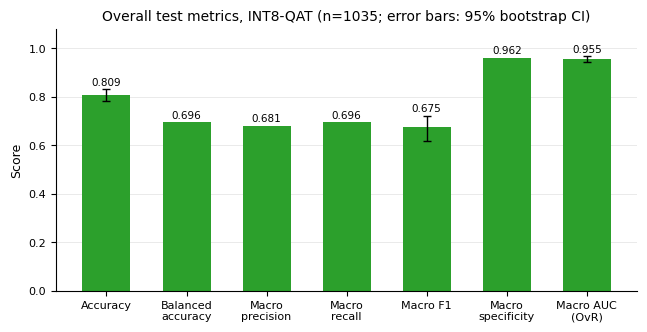

In [11]:
# 1. Overall metrics, with 95% bootstrap CIs where computed
names = {"accuracy": "Accuracy", "balanced_accuracy": "Balanced\naccuracy", "macro_precision": "Macro\nprecision",
         "macro_recall": "Macro\nrecall", "macro_f1": "Macro F1", "macro_specificity": "Macro\nspecificity",
         "macro_auc_ovr": "Macro AUC\n(OvR)"}
keys = list(names)
values = [overall[k] for k in keys]
err = np.array([[overall[k] - ci95[k][0], ci95[k][1] - overall[k]] if k in ci95 else [0, 0] for k in keys]).T

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(range(len(keys)), values, color=COLOR, width=0.6)
has_ci = [k in ci95 for k in keys]
ax.errorbar(np.arange(len(keys))[has_ci], np.array(values)[has_ci], yerr=err[:, has_ci],
            fmt="none", ecolor="black", elinewidth=1, capsize=3)
for i, v in enumerate(values):
    ax.text(i, v + (err[1, i] if has_ci[i] else 0) + 0.015, f"{v:.3f}", ha="center", fontsize=7.5)
ax.set_xticks(range(len(keys)))
ax.set_xticklabels([names[k] for k in keys])
ax.set_ylim(0, 1.08)
ax.set_ylabel("Score")
ax.set_title(f"Overall test metrics, {MODEL_LABEL} (n={len(y_true)}; error bars: 95% bootstrap CI)")
ax.grid(axis="x", visible=False)
save_fig(fig, "1_overall_metrics")
plt.show()

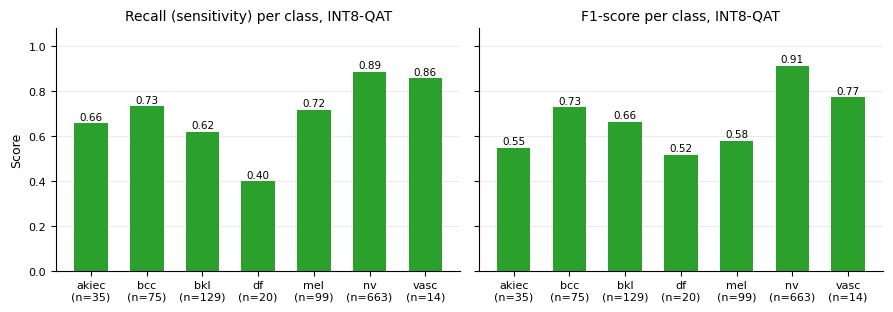

In [12]:
# 2. Per-class recall and F1
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
x = np.arange(len(class_names))
xlabels = [f"{c}\n(n={n})" for c, n in zip(class_names, per_class["support"])]
for ax, col, title in zip(axes, ["recall", "f1"], ["Recall (sensitivity) per class", "F1-score per class"]):
    ax.bar(x, per_class[col], color=COLOR, width=0.6)
    for i, v in enumerate(per_class[col]):
        ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=7.5)
    ax.set_xticks(x)
    ax.set_xticklabels(xlabels)
    ax.set_ylim(0, 1.08)
    ax.set_title(f"{title}, {MODEL_LABEL}")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score")
fig.tight_layout()
save_fig(fig, "2_per_class_recall_f1")
plt.show()

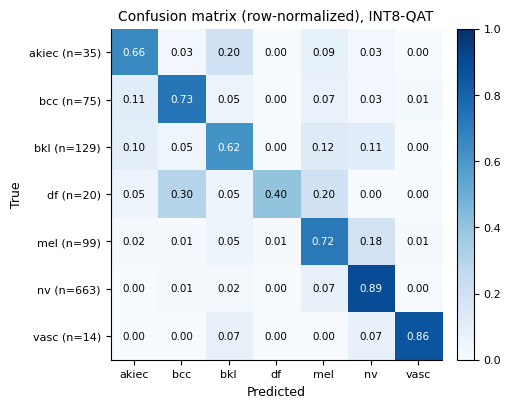

In [13]:
# 3. Row-normalized confusion matrix
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for (r, c), v in np.ndenumerate(cm_norm):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.6 else "black")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_yticks(x)
ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(class_names, per_class["support"])])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"Confusion matrix (row-normalized), {MODEL_LABEL}")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
save_fig(fig, "3_confusion_matrix")
plt.show()

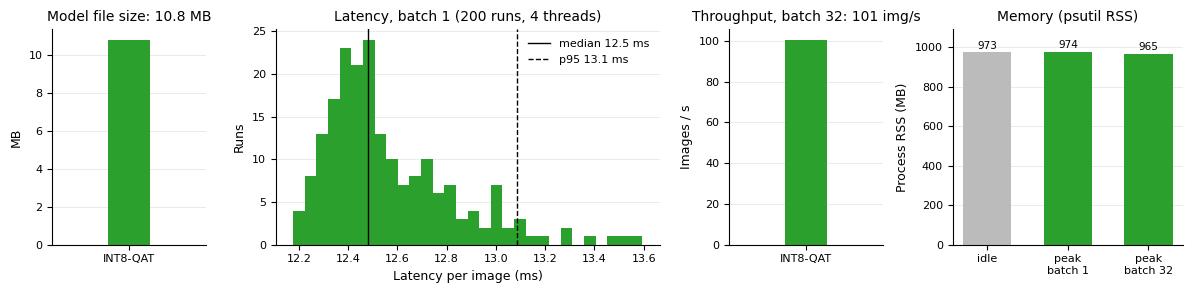

In [14]:
# 4. Efficiency: size, latency distribution, throughput, memory
fig, axes = plt.subplots(1, 4, figsize=(12, 3), gridspec_kw={"width_ratios": [0.8, 2, 0.8, 1.2]})

axes[0].bar([MODEL_LABEL], [model_size_mb], color=COLOR, width=0.5)
axes[0].set_ylabel("MB")
axes[0].set_title(f"Model file size: {model_size_mb:.1f} MB")
axes[0].set_xlim(-0.9, 0.9)

lat = efficiency["latency_bs1_ms"]
axes[1].hist(latency_ms, bins=30, color=COLOR)
for v, ls, name in [(lat["median"], "-", "median"), (lat["p95"], "--", "p95")]:
    axes[1].axvline(v, color="black", linestyle=ls, linewidth=1, label=f"{name} {v:.1f} ms")
axes[1].set_xlabel("Latency per image (ms)")
axes[1].set_ylabel("Runs")
axes[1].set_title(f"Latency, batch 1 ({lat['runs']} runs, {NUM_THREADS} threads)")
axes[1].legend(frameon=False)

tp = efficiency["throughput_bs32_ips"]["images_per_s"]
axes[2].bar([MODEL_LABEL], [tp], color=COLOR, width=0.5)
axes[2].set_ylabel("Images / s")
axes[2].set_title(f"Throughput, batch 32: {tp:.0f} img/s")
axes[2].set_xlim(-0.9, 0.9)

mem = efficiency["memory_rss_mb"]
mem_vals = [mem["idle"], mem["peak_bs1"], mem["peak_bs32"]]
axes[3].bar(["idle", "peak\nbatch 1", "peak\nbatch 32"], mem_vals, color=["#bbbbbb", COLOR, COLOR], width=0.6)
for i, v in enumerate(mem_vals):
    axes[3].text(i, v * 1.01, f"{v:.0f}", ha="center", va="bottom", fontsize=7.5)
axes[3].set_ylim(0, max(mem_vals) * 1.12)
axes[3].set_ylabel("Process RSS (MB)")
axes[3].set_title("Memory (psutil RSS)")
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save_fig(fig, "4_efficiency")
plt.show()

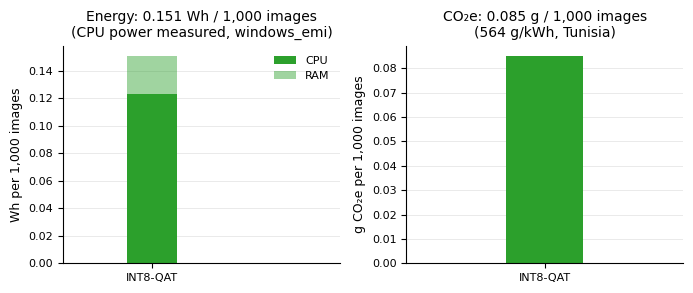

In [15]:
# 5. Energy and CO2e per 1,000 images (only if measured)
if energy is None:
    print("No energy measurement: plot skipped")
else:
    fig, axes = plt.subplots(1, 2, figsize=(7, 3))
    axes[0].bar([MODEL_LABEL], [energy["cpu_wh_per_1000_images"]], color=COLOR, width=0.5, label="CPU")
    axes[0].bar([MODEL_LABEL], [energy["ram_wh_per_1000_images"]], bottom=[energy["cpu_wh_per_1000_images"]],
                color=COLOR, alpha=0.45, width=0.5, label="RAM")
    axes[0].set_ylabel("Wh per 1,000 images")
    axes[0].set_title(f"Energy: {energy['wh_per_1000_images']:.3f} Wh / 1,000 images\n"
                      f"(CPU power {energy['cpu_power_source']}, {energy['cpu_power_mode']})")
    axes[0].set_xlim(-0.9, 1.9)  # room on the right for the legend
    axes[0].legend(frameon=False, loc="upper right")
    axes[1].bar([MODEL_LABEL], [energy["g_co2e_per_1000_images"]], color=COLOR, width=0.5)
    axes[1].set_xlim(-0.9, 0.9)
    axes[1].set_ylabel("g CO₂e per 1,000 images")
    axes[1].set_title(f"CO₂e: {energy['g_co2e_per_1000_images']:.3f} g / 1,000 images\n"
                      f"({energy['carbon_intensity_g_per_kwh']:.0f} g/kWh, {energy['country']})")
    for ax in axes:
        ax.grid(axis="x", visible=False)
    fig.tight_layout()
    save_fig(fig, "5_energy_co2e")
    plt.show()

## Summary

In [16]:
rows = [
    ("Accuracy", f"{overall['accuracy']:.4f} [{ci95['accuracy'][0]:.4f}, {ci95['accuracy'][1]:.4f}]"),
    ("Balanced accuracy", f"{overall['balanced_accuracy']:.4f}"),
    ("Macro precision", f"{overall['macro_precision']:.4f}"),
    ("Macro recall", f"{overall['macro_recall']:.4f}"),
    ("Macro F1", f"{overall['macro_f1']:.4f} [{ci95['macro_f1'][0]:.4f}, {ci95['macro_f1'][1]:.4f}]"),
    ("Macro specificity", f"{overall['macro_specificity']:.4f}"),
    ("Macro AUC (OvR)", f"{overall['macro_auc_ovr']:.4f} [{ci95['macro_auc_ovr'][0]:.4f}, {ci95['macro_auc_ovr'][1]:.4f}]"),
    ("Model size", f"{model_size_mb:.2f} MB"),
    ("GMACs", f"{gmacs:.3f}" + ("" if MODEL_LABEL == "FP32" else " (FP32 architecture count)")),
    ("Latency bs=1 median / p95", f"{lat['median']:.2f} / {lat['p95']:.2f} ms"),
    ("Throughput bs=32", f"{tp:.1f} images/s"),
    ("Peak RSS bs=32", f"{mem['peak_bs32']:.0f} MB"),
]
if energy:
    rows += [("Energy (CPU+RAM)", f"{energy['wh_per_1000_images']:.3f} Wh / 1,000 images"),
             ("CO₂e", f"{energy['g_co2e_per_1000_images']:.3f} g / 1,000 images"),
             ("CPU power", f"{energy['cpu_power_source']} ({energy['cpu_power_mode']})")]
print(pd.DataFrame(rows, columns=[f"{MODEL_LABEL} metric", "value [95% CI]"]).to_string(index=False))

          INT8-QAT metric                  value [95% CI]
                 Accuracy         0.8087 [0.7845, 0.8329]
        Balanced accuracy                          0.6960
          Macro precision                          0.6813
             Macro recall                          0.6960
                 Macro F1         0.6748 [0.6171, 0.7227]
        Macro specificity                          0.9617
          Macro AUC (OvR)         0.9547 [0.9413, 0.9663]
               Model size                        10.80 MB
                    GMACs 1.825 (FP32 architecture count)
Latency bs=1 median / p95                12.48 / 13.08 ms
         Throughput bs=32                  100.6 images/s
           Peak RSS bs=32                          965 MB
         Energy (CPU+RAM)         0.151 Wh / 1,000 images
                     CO₂e          0.085 g / 1,000 images
                CPU power          measured (windows_emi)
